# NPL-only model comparison

Save the chronological split, prepare transformations and lagged predictors, and compare NPL-only ARIMA candidates using pre-2022 data. ARX specifications are explored in Notebook 4; validation and forecasting are deferred to Notebook 5.

## Imports and configuration

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = Path("../data/raw/kazakhstan_npl_oil_fx_quarterly.csv")
PROCESSED_DIRECTORY = Path("../data/processed")
TRAIN_DATA_PATH = PROCESSED_DIRECTORY / "train.csv"
TEST_DATA_PATH = PROCESSED_DIRECTORY / "test.csv"
EXPECTED_COLUMNS = ["quarter", "npl", "brent", "usdkzt"]
VALUE_COLUMNS = EXPECTED_COLUMNS[1:]
TRAIN_END = pd.Period("2021Q4", freq="Q-DEC")
MAX_FEATURE_LAG = 4
ARIMA_P_VALUES = [0, 1, 2]
ARIMA_Q_VALUES = [0, 1, 2]
ARIMA_D = 0
ARIMA_RESIDUAL_LAG = 8
ARIMA_DIAGNOSTIC_BURN_IN = max(ARIMA_P_VALUES + ARIMA_Q_VALUES)
TARGET_COLUMN = "npl_change_pp"
CHANGE_COLUMNS = [
    TARGET_COLUMN,
    "brent_log_change_pct",
    "usdkzt_log_change_pct",
]

assert DATA_PATH.exists(), f"Missing input: {DATA_PATH}"

## Data import and checks

In [2]:
quarterly_data = pd.read_csv(DATA_PATH)
display(quarterly_data.head())
quarterly_data.info()

assert quarterly_data.columns.tolist() == EXPECTED_COLUMNS
assert quarterly_data["quarter"].str.fullmatch(r"\d{4}Q[1-4]").all()
assert quarterly_data[VALUE_COLUMNS].select_dtypes(include=np.number).shape[1] == 3
assert not quarterly_data.isna().any().any()
assert np.isfinite(quarterly_data[VALUE_COLUMNS].to_numpy()).all()
assert quarterly_data["npl"].between(0, 100).all()
assert quarterly_data[["brent", "usdkzt"]].gt(0).all().all()

quarter_index = pd.PeriodIndex(quarterly_data["quarter"], freq="Q-DEC")
expected_quarters = pd.period_range("2010Q1", "2026Q2", freq="Q-DEC")
assert quarter_index.equals(expected_quarters)
assert quarter_index.is_unique

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   quarter  66 non-null     object 
 1   npl      66 non-null     float64
 2   brent    66 non-null     float64
 3   usdkzt   66 non-null     float64
dtypes: float64(3), object(1)
memory usage: 2.2+ KB


,quarter,npl,brent,usdkzt
0,2010Q1,24.9600,76.6700,147.7000
1,2010Q2,25.2500,78.8500,146.8100
2,2010Q3,25.8300,76.6800,147.4100
3,2010Q4,23.7500,87.0300,147.4900
4,2011Q1,25.2700,105.3700,146.4200


## Chronological split

Train on 2010Q1–2021Q4 (48 quarters) and reserve 2022Q1–2026Q2 (18 quarters) for later evaluation. The validation/final-test subdivision is not defined here.

In [3]:
# split chronologically before transforming or fitting models
time_series_data = quarterly_data[VALUE_COLUMNS].copy()
time_series_data.index = quarter_index
time_series_data.index.name = "quarter"
train_data = time_series_data.loc[time_series_data.index <= TRAIN_END].copy()
test_data = time_series_data.loc[time_series_data.index > TRAIN_END].copy()

assert len(train_data) == 48 and len(test_data) == 18
assert train_data.index.intersection(test_data.index).empty
assert train_data.index.max() < test_data.index.min()

split_summary = pd.DataFrame([
    {
        "sample": name,
        "start": str(sample.index.min()),
        "end": str(sample.index.max()),
        "quarters": len(sample),
    }
    for name, sample in [("training", train_data), ("test", test_data)]
]).set_index("sample")
display(split_summary)

,start,end,quarters
sample,,,
training,2010Q1,2021Q4,48
test,2022Q1,2026Q2,18


### Save split datasets

Export original levels to `data/processed/train.csv` and `data/processed/test.csv`. Preserve the four source columns and two-decimal values; transformations and lags are not exported.

In [4]:
# save original levels in separate files before any transformations
PROCESSED_DIRECTORY.mkdir(parents=True, exist_ok=True)
for sample, path in [(train_data, TRAIN_DATA_PATH), (test_data, TEST_DATA_PATH)]:
    export_data = sample.reset_index()
    export_data["quarter"] = export_data["quarter"].astype(str)
    assert export_data.columns.tolist() == EXPECTED_COLUMNS
    export_data.to_csv(path, index=False, float_format="%.2f")

    # check that two-decimal formatting preserves every source value
    pd.testing.assert_frame_equal(
        pd.read_csv(path), export_data, check_exact=True
    )

# verify that the saved files reconstruct the complete source dataset
saved_split_data = pd.concat(
    [pd.read_csv(TRAIN_DATA_PATH), pd.read_csv(TEST_DATA_PATH)],
    ignore_index=True,
)
pd.testing.assert_frame_equal(saved_split_data, quarterly_data, check_exact=True)
display(split_summary.assign(
    file=[str(TRAIN_DATA_PATH), str(TEST_DATA_PATH)]
))

,start,end,quarters,file
sample,,,,
training,2010Q1,2021Q4,48,../data/processed/train.csv
test,2022Q1,2026Q2,18,../data/processed/test.csv


## Forecast target and timing

Rows identify target quarter $t$. Predict $\Delta NPL_t$ from earlier observations, then reconstruct the level as $\widehat{NPL}_t=NPL_{t-1}+\widehat{\Delta NPL}_t$.

Candidate predictors use changes at $t-1$ through $t-4$, not current-quarter values. No 2022+ observations enter model fitting.

## Transformations

Reuse Notebook 2's transformations on training data, retaining original levels.

| Series | Transformation | Unit |
| --- | --- | --- |
| NPL | First difference | Percentage points |
| Brent | 100 × log difference | Approximately quarterly percent change |
| USD/KZT | 100 × log difference | Approximately quarterly percent change; positive means depreciation |

No scaling, additional rounding or outlier removal is applied.

In [5]:
transformed_train = train_data.copy()

# retain levels and calculate changes without using final-test observations
transformed_train[TARGET_COLUMN] = train_data["npl"].diff()
transformed_train["brent_log_change_pct"] = (
    np.log(train_data["brent"]).diff() * 100
)
transformed_train["usdkzt_log_change_pct"] = (
    np.log(train_data["usdkzt"]).diff() * 100
)

pd.testing.assert_frame_equal(transformed_train[VALUE_COLUMNS], train_data)
assert transformed_train.index.max() == TRAIN_END
assert transformed_train.index.intersection(test_data.index).empty
assert transformed_train[CHANGE_COLUMNS].iloc[0].isna().all()
assert transformed_train[CHANGE_COLUMNS].iloc[1:].notna().all().all()
assert np.isfinite(transformed_train[CHANGE_COLUMNS].iloc[1:].to_numpy()).all()
display(transformed_train.head())

,npl,brent,usdkzt,npl_change_pp,brent_log_change_pct,usdkzt_log_change_pct
quarter,,,,,,
2010Q1,24.9600,76.6700,147.7000,NaN,NaN,NaN
2010Q2,25.2500,78.8500,146.8100,0.2900,2.8037,-0.6044
2010Q3,25.8300,76.6800,147.4100,0.5800,-2.7906,0.4079
2010Q4,23.7500,87.0300,147.4900,-2.0800,12.6612,0.0543
2011Q1,25.2700,105.3700,146.4200,1.5200,19.1225,-0.7281


## Lagged predictors

Create lags 1–4 of the three change series: 12 candidate predictors. Shift before removing missing rows to preserve quarterly timing. This is a candidate pool, not a selected model.

In [6]:
training_features = transformed_train[[TARGET_COLUMN]].copy()
feature_rows = []

# generate past-only predictors and check the missing prefix for each lag
for column in CHANGE_COLUMNS:
    for lag in range(1, MAX_FEATURE_LAG + 1):
        feature = f"{column}_lag_{lag}"
        training_features[feature] = transformed_train[column].shift(lag)
        assert training_features[feature].iloc[:lag + 1].isna().all()
        assert training_features[feature].iloc[lag + 1:].notna().all()
        available_values = training_features[feature].dropna()
        feature_rows.append({
            "feature": feature,
            "source_series": column,
            "lag_quarters": lag,
            "available_rows": len(available_values),
            "first_target_quarter": str(available_values.index.min()),
            "last_target_quarter": str(available_values.index.max()),
        })

feature_summary = pd.DataFrame(feature_rows)
LAGGED_FEATURE_COLUMNS = feature_summary["feature"].tolist()
assert len(LAGGED_FEATURE_COLUMNS) == len(CHANGE_COLUMNS) * MAX_FEATURE_LAG == 12
assert feature_summary["lag_quarters"].between(1, 4).all()
assert training_features.index.equals(train_data.index)
display(feature_summary)

,feature,source_series,lag_quarters,available_rows,first_target_quarter,last_target_quarter
0,npl_change_pp_lag_1,npl_change_pp,1,46,2010Q3,2021Q4
1,npl_change_pp_lag_2,npl_change_pp,2,45,2010Q4,2021Q4
2,npl_change_pp_lag_3,npl_change_pp,3,44,2011Q1,2021Q4
3,npl_change_pp_lag_4,npl_change_pp,4,43,2011Q2,2021Q4
4,brent_log_change_pct_lag_1,brent_log_change_pct,1,46,2010Q3,2021Q4
5,brent_log_change_pct_lag_2,brent_log_change_pct,2,45,2010Q4,2021Q4
6,brent_log_change_pct_lag_3,brent_log_change_pct,3,44,2011Q1,2021Q4
7,brent_log_change_pct_lag_4,brent_log_change_pct,4,43,2011Q2,2021Q4
8,usdkzt_log_change_pct_lag_1,usdkzt_log_change_pct,1,46,2010Q3,2021Q4
9,usdkzt_log_change_pct_lag_2,usdkzt_log_change_pct,2,45,2010Q4,2021Q4


### Sample alignment

The common lagged-regression sample contains 43 target quarters (2011Q2–2021Q4). Only initial rows lost to differencing and lags are excluded.

Keep predictors (`X_train`) separate from the target (`y_train`). NPL-only ARIMA uses all 47 available changes because it does not require the macro-lag columns.

In [7]:
# align the target and all candidate predictors on one common sample
model_data = training_features.dropna().copy()
assert model_data.index.equals(train_data.index[MAX_FEATURE_LAG + 1:])
assert len(model_data) == len(train_data) - MAX_FEATURE_LAG - 1 == 43
assert model_data.index.intersection(test_data.index).empty
assert np.isfinite(model_data.to_numpy()).all()

X_train = model_data[LAGGED_FEATURE_COLUMNS].copy()
y_train = model_data[TARGET_COLUMN].copy()
assert X_train.index.equals(y_train.index)
assert TARGET_COLUMN not in X_train.columns
assert not set(VALUE_COLUMNS).intersection(X_train.columns)

# verify every lag against the exact earlier quarter, not just row counts
for row in feature_rows:
    source_quarters = model_data.index - row["lag_quarters"]
    expected_values = transformed_train.loc[
        source_quarters, row["source_series"]
    ].set_axis(model_data.index)
    pd.testing.assert_series_equal(
        X_train[row["feature"]], expected_values,
        check_names=False, check_exact=True,
    )
    assert (source_quarters <= model_data.index - 1).all()

forecast_alignment = pd.DataFrame({
    "target_quarter": model_data.index,
    "forecast_origin_quarter": model_data.index - 1,
    "latest_observed_npl": train_data["npl"].shift(1).loc[model_data.index],
}, index=model_data.index)
assert (
    forecast_alignment["target_quarter"]
    == forecast_alignment["forecast_origin_quarter"] + 1
).all()

# confirm that the change target reconstructs the original npl level
np.testing.assert_allclose(
    forecast_alignment["latest_observed_npl"] + y_train,
    train_data.loc[model_data.index, "npl"],
    rtol=0, atol=1e-12,
)

display(pd.DataFrame({
    "first_target_quarter": [str(model_data.index.min())],
    "last_target_quarter": [str(model_data.index.max())],
    "complete_rows": [len(model_data)],
    "candidate_predictors": [X_train.shape[1]],
}))
display(forecast_alignment.head())
display(model_data.head())

,first_target_quarter,last_target_quarter,complete_rows,candidate_predictors
0,2011Q2,2021Q4,43,12


,target_quarter,forecast_origin_quarter,latest_observed_npl
quarter,,,
2011Q2,2011Q2,2011Q1,25.2700
2011Q3,2011Q3,2011Q2,26.2700
2011Q4,2011Q4,2011Q3,29.4600
2012Q1,2012Q1,2011Q4,30.6000
2012Q2,2012Q2,2012Q1,31.9000


,npl_change_pp,npl_change_pp_lag_1,npl_change_pp_lag_2,npl_change_pp_lag_3,npl_change_pp_lag_4,brent_log_change_pct_lag_1,brent_log_change_pct_lag_2,brent_log_change_pct_lag_3,brent_log_change_pct_lag_4,usdkzt_log_change_pct_lag_1,usdkzt_log_change_pct_lag_2,usdkzt_log_change_pct_lag_3,usdkzt_log_change_pct_lag_4
quarter,,,,,,,,,,,,,
2011Q2,1.0000,1.5200,-2.0800,0.5800,0.2900,19.1225,12.6612,-2.7906,2.8037,-0.7281,0.0543,0.4079,-0.6044
2011Q3,3.1900,1.0000,1.5200,-2.0800,0.5800,10.9301,19.1225,12.6612,-2.7906,-0.5685,-0.7281,0.0543,0.4079
2011Q4,1.1400,3.1900,1.0000,1.5200,-2.0800,-3.7004,10.9301,19.1225,12.6612,0.6640,-0.5685,-0.7281,0.0543
2012Q1,1.3000,1.1400,3.1900,1.0000,1.5200,-2.9476,-3.7004,10.9301,19.1225,0.9169,0.6640,-0.5685,-0.7281
2012Q2,-1.0000,1.3000,1.1400,3.1900,1.0000,7.4024,-2.9476,-3.7004,10.9301,0.1554,0.9169,0.6640,-0.5685


## NPL-only ARIMA comparison

Treat NPL changes as an $I(0)$ candidate and use `d=0`: the levels have already been differenced. The corresponding level specification is ARIMA(p,1,q), with matching drift.

Fit nine combinations with p,q ∈ {0,1,2} on 47 changes (2010Q2–2021Q4), with a constant mean and no seasonal terms. These include AR, MA and ARMA specifications, estimated through [ARIMA](https://www.statsmodels.org/v0.14.0/generated/statsmodels.tsa.arima.model.ARIMA.html). The constant-mean (0,0,0) model is not zero-change persistence.

Compare information criteria only across these equal-sample fits, not with the 43-row regression sample. Root-modulus values are undefined (NaN) where the AR or MA component is absent.

In [8]:
# use every available pre-2022 npl change, not the shorter lagged-feature sample
arima_target = transformed_train[TARGET_COLUMN].dropna().copy()
assert arima_target.index.equals(train_data.index[1:])
assert len(arima_target) == 47
assert arima_target.index.max() == TRAIN_END
assert arima_target.index.intersection(test_data.index).empty
assert np.isfinite(arima_target.to_numpy()).all()

arima_results = {}
fit_rows = []
warning_rows = []

# fit pure ar, pure ma and mixed orders with no additional differencing
for p in ARIMA_P_VALUES:
    for q in ARIMA_Q_VALUES:
        order = (p, ARIMA_D, q)
        model_name = f"ARIMA{order}"
        with warnings.catch_warnings(record=True) as recorded:
            warnings.simplefilter("always")
            result = ARIMA(
                arima_target,
                order=order,
                trend="c",
                enforce_stationarity=True,
                enforce_invertibility=True,
            ).fit(method_kwargs={"maxiter": 1000})

        for warning in recorded:
            warning_rows.append({
                "model": model_name,
                "category": warning.category.__name__,
                "message": str(warning.message),
            })

        assert result.nobs == len(arima_target)
        assert np.isfinite(result.params.to_numpy()).all()
        assert np.isfinite([result.llf, result.aic, result.aicc, result.bic]).all()
        arima_results[model_name] = result
        fit_rows.append({
            "model": model_name,
            "p": p,
            "d": ARIMA_D,
            "q": q,
            "observations": int(result.nobs),
            "parameters": len(result.params),
            "converged": bool(result.mle_retvals.get("converged", False)),
            "aic": result.aic,
            "aicc": result.aicc,
            "bic": result.bic,
            "min_ar_root_modulus": (
                np.min(np.abs(result.arroots)) if p > 0 else np.nan
            ),
            "min_ma_root_modulus": (
                np.min(np.abs(result.maroots)) if q > 0 else np.nan
            ),
        })

arima_fit_comparison = (
    pd.DataFrame(fit_rows).set_index("model").sort_values("aicc")
)
arima_fit_comparison["delta_aicc"] = (
    arima_fit_comparison["aicc"] - arima_fit_comparison["aicc"].min()
)
assert len(arima_results) == len(ARIMA_P_VALUES) * len(ARIMA_Q_VALUES) == 9
assert set(zip(arima_fit_comparison["p"], arima_fit_comparison["q"])) == {
    (p, q) for p in ARIMA_P_VALUES for q in ARIMA_Q_VALUES
}
for order_column, root_column in [
    ("p", "min_ar_root_modulus"), ("q", "min_ma_root_modulus")
]:
    absent_component = arima_fit_comparison[order_column].eq(0)
    assert arima_fit_comparison.loc[absent_component, root_column].isna().all()
    assert arima_fit_comparison.loc[~absent_component, root_column].gt(1).all()
display(arima_fit_comparison)

# retain fit warnings explicitly rather than suppressing them globally
arima_fit_warnings = pd.DataFrame(
    warning_rows, columns=["model", "category", "message"]
)
if arima_fit_warnings.empty:
    print("No fit warnings recorded.")
else:
    display(arima_fit_warnings)

No fit warnings recorded.


,p,d,q,observations,parameters,converged,aic,aicc,bic,min_ar_root_modulus,min_ma_root_modulus,delta_aicc
model,,,,,,,,,,,,
"ARIMA(2, 0, 0)",2,0,0,47,4,True,221.9913,222.9437,229.3919,1.7131,NaN,0.0000
"ARIMA(0, 0, 2)",0,0,2,47,4,True,222.1964,223.1487,229.5969,NaN,1.8251,0.2050
"ARIMA(0, 0, 0)",0,0,0,47,2,True,223.1801,223.4528,226.8804,NaN,NaN,0.5091
"ARIMA(2, 0, 1)",2,0,1,47,5,True,223.8141,225.2775,233.0648,1.5906,5.2025,2.3338
"ARIMA(1, 0, 2)",1,0,2,47,5,True,223.9028,225.3663,233.1536,4.1948,1.7921,2.4226
"ARIMA(1, 0, 0)",1,0,0,47,3,True,224.8618,225.4199,230.4122,12.2835,NaN,2.4762
"ARIMA(0, 0, 1)",0,0,1,47,3,True,224.9855,225.5436,230.5359,NaN,20.0758,2.5999
"ARIMA(1, 0, 1)",1,0,1,47,4,True,225.6204,226.5728,233.0210,1.5668,2.0035,3.6291
"ARIMA(2, 0, 2)",2,0,2,47,6,True,225.8138,227.9138,236.9147,1.6133,7.9467,4.9701


### Coefficients

`const` estimates mean NPL change in percentage points, not the expanded AR equation's intercept. AR/MA coefficients describe dynamics; `sigma2` is innovation variance.

Coefficient p-values are conditional on each specification, not a model-selection rule. Small-sample uncertainty and genuine portfolio jumps limit interpretation.

In [9]:
# display parameter estimates and uncertainty for every requested fit
coefficient_rows = []
for model_name, result in arima_results.items():
    intervals = result.conf_int(alpha=0.05)
    for parameter in result.params.index:
        coefficient_rows.append({
            "model": model_name,
            "parameter": parameter,
            "estimate": result.params.loc[parameter],
            "standard_error": result.bse.loc[parameter],
            "p_value": result.pvalues.loc[parameter],
            "lower_95": intervals.loc[parameter].iloc[0],
            "upper_95": intervals.loc[parameter].iloc[1],
        })

arima_coefficients = pd.DataFrame(coefficient_rows).set_index(
    ["model", "parameter"]
)
assert np.isfinite(arima_coefficients.to_numpy()).all()
display(arima_coefficients)

estimate  standard_error  p_value  lower_95  \
model          parameter                                                
ARIMA(0, 0, 0) const       -0.4606          0.5897   0.4347   -1.6165   
               sigma2       6.2061          0.7443   0.0000    4.7474   
ARIMA(0, 0, 1) const       -0.4605          0.6413   0.4727   -1.7175   
               ma.L1        0.0498          0.2937   0.8653   -0.5258   
               sigma2       6.1801          0.7469   0.0000    4.7162   
ARIMA(0, 0, 2) const       -0.4482          0.7046   0.5247   -1.8292   
               ma.L1        0.0416          0.1863   0.8235   -0.3236   
               ma.L2        0.3002          0.1503   0.0458    0.0055   
               sigma2       5.5592          1.0520   0.0000    3.4973   
ARIMA(1, 0, 0) const       -0.4604          0.6643   0.4883   -1.7623   
               ar.L1        0.0814          0.2752   0.7674   -0.4580   
               sigma2       6.1633          0.7501   0.0000    4.6930   
ARIMA(1, 0, 1) const       -0.4575          0.8602   0.5948   -2.1434   
               ar.L1        0.6382          0.9045   0.4804   -1.1345   
               ma.L1       -0.4991          0.9664   0.6055   -2.3932   
               sigma2       5.9980          1.1874   0.0000    3.6707   
ARIMA(1, 0, 2) const       -0.4491          0.8132   0.5808   -2.0429   
               ar.L1        0.2384          1.0508   0.8205   -1.8211   
               ma.L1       -0.1810          0.8091   0.8230   -1.7667   
               ma.L2        0.3114          0.2450   0.2037   -0.1688   
               sigma2       5.5198          1.0721   0.0000    3.4185   
ARIMA(2, 0, 0) const       -0.4479          0.8423   0.5949   -2.0987   
               ar.L1        0.0561          0.2605   0.8294   -0.4545   
               ar.L2        0.3080          0.1046   0.0032    0.1029   
               sigma2       5.5331          0.8544   0.0000    3.8585   
ARIMA(2, 0, 1) const       -0.4440          0.9547   0.6419   -2.3151   
               ar.L1       -0.1157          1.1640   0.9208   -2.3970   
               ar.L2        0.3225          0.1348   0.0167    0.0583   
               ma.L1        0.1922          1.0585   0.8559   -1.8824   
               sigma2       5.5110          1.1117   0.0000    3.3321   
ARIMA(2, 0, 2) const       -0.4440          1.0554   0.6739   -2.5125   
               ar.L1       -0.1108          1.2308   0.9283   -2.5230   
               ar.L2        0.3156          1.4792   0.8311   -2.5837   
               ma.L1        0.1868          1.0597   0.8601   -1.8902   
               ma.L2        0.0077          1.6123   0.9962   -3.1524   
               sigma2       5.5110          1.1177   0.0000    3.3204   

                          upper_95  
model          parameter            
ARIMA(0, 0, 0) const        0.6952  
               sigma2       7.6648  
ARIMA(0, 0, 1) const        0.7965  
               ma.L1        0.6254  
               sigma2       7.6440  
ARIMA(0, 0, 2) const        0.9328  
               ma.L1        0.4067  
               ma.L2        0.5949  
               sigma2       7.6210  
ARIMA(1, 0, 0) const        0.8415  
               ar.L1        0.6208  
               sigma2       7.6335  
ARIMA(1, 0, 1) const        1.2284  
               ar.L1        2.4110  
               ma.L1        1.3950  
               sigma2       8.3253  
ARIMA(1, 0, 2) const        1.1447  
               ar.L1        2.2979  
               ma.L1        1.4048  
               ma.L2        0.7915  
               sigma2       7.6212  
ARIMA(2, 0, 0) const        1.2030  
               ar.L1        0.5668  
               ar.L2        0.5130  
               sigma2       7.2076  
ARIMA(2, 0, 1) const        1.4272  
               ar.L1        2.1656  
               ar.L2        0.5867  
               ma.L1        2.2668  
               sigma2       7.6898  
ARIMA(2, 0, 2) const        1.6245  
               ar.L1        2.

### Residual diagnostics

Inspect standardized one-step innovations with ACF/PACF and the [Ljung–Box test](https://www.statsmodels.org/v0.14.0/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html) through lag 8, adjusting degrees of freedom by p+q.

Exclude the first two quarters from diagnostics only; all 47 changes remain in estimation. Large p-values mean dependence was not detected, not proof of white noise. Plot bands are pointwise.

,diagnostic_observations,excluded_initial_quarters,test_lag,model_df,ljung_box_stat,ljung_box_p,reject_at_5pct
model,,,,,,,
"ARIMA(0, 0, 0)",45,2,8,0,8.2680,0.4077,False
"ARIMA(0, 0, 1)",45,2,8,1,7.8735,0.3439,False
"ARIMA(0, 0, 2)",45,2,8,2,2.5458,0.8633,False
"ARIMA(1, 0, 0)",45,2,8,1,7.7581,0.3544,False
"ARIMA(1, 0, 1)",45,2,8,2,6.8491,0.3350,False
"ARIMA(1, 0, 2)",45,2,8,3,1.9560,0.8552,False
"ARIMA(2, 0, 0)",45,2,8,2,2.3918,0.8804,False
"ARIMA(2, 0, 1)",45,2,8,3,2.3182,0.8036,False
"ARIMA(2, 0, 2)",45,2,8,4,2.3099,0.6790,False


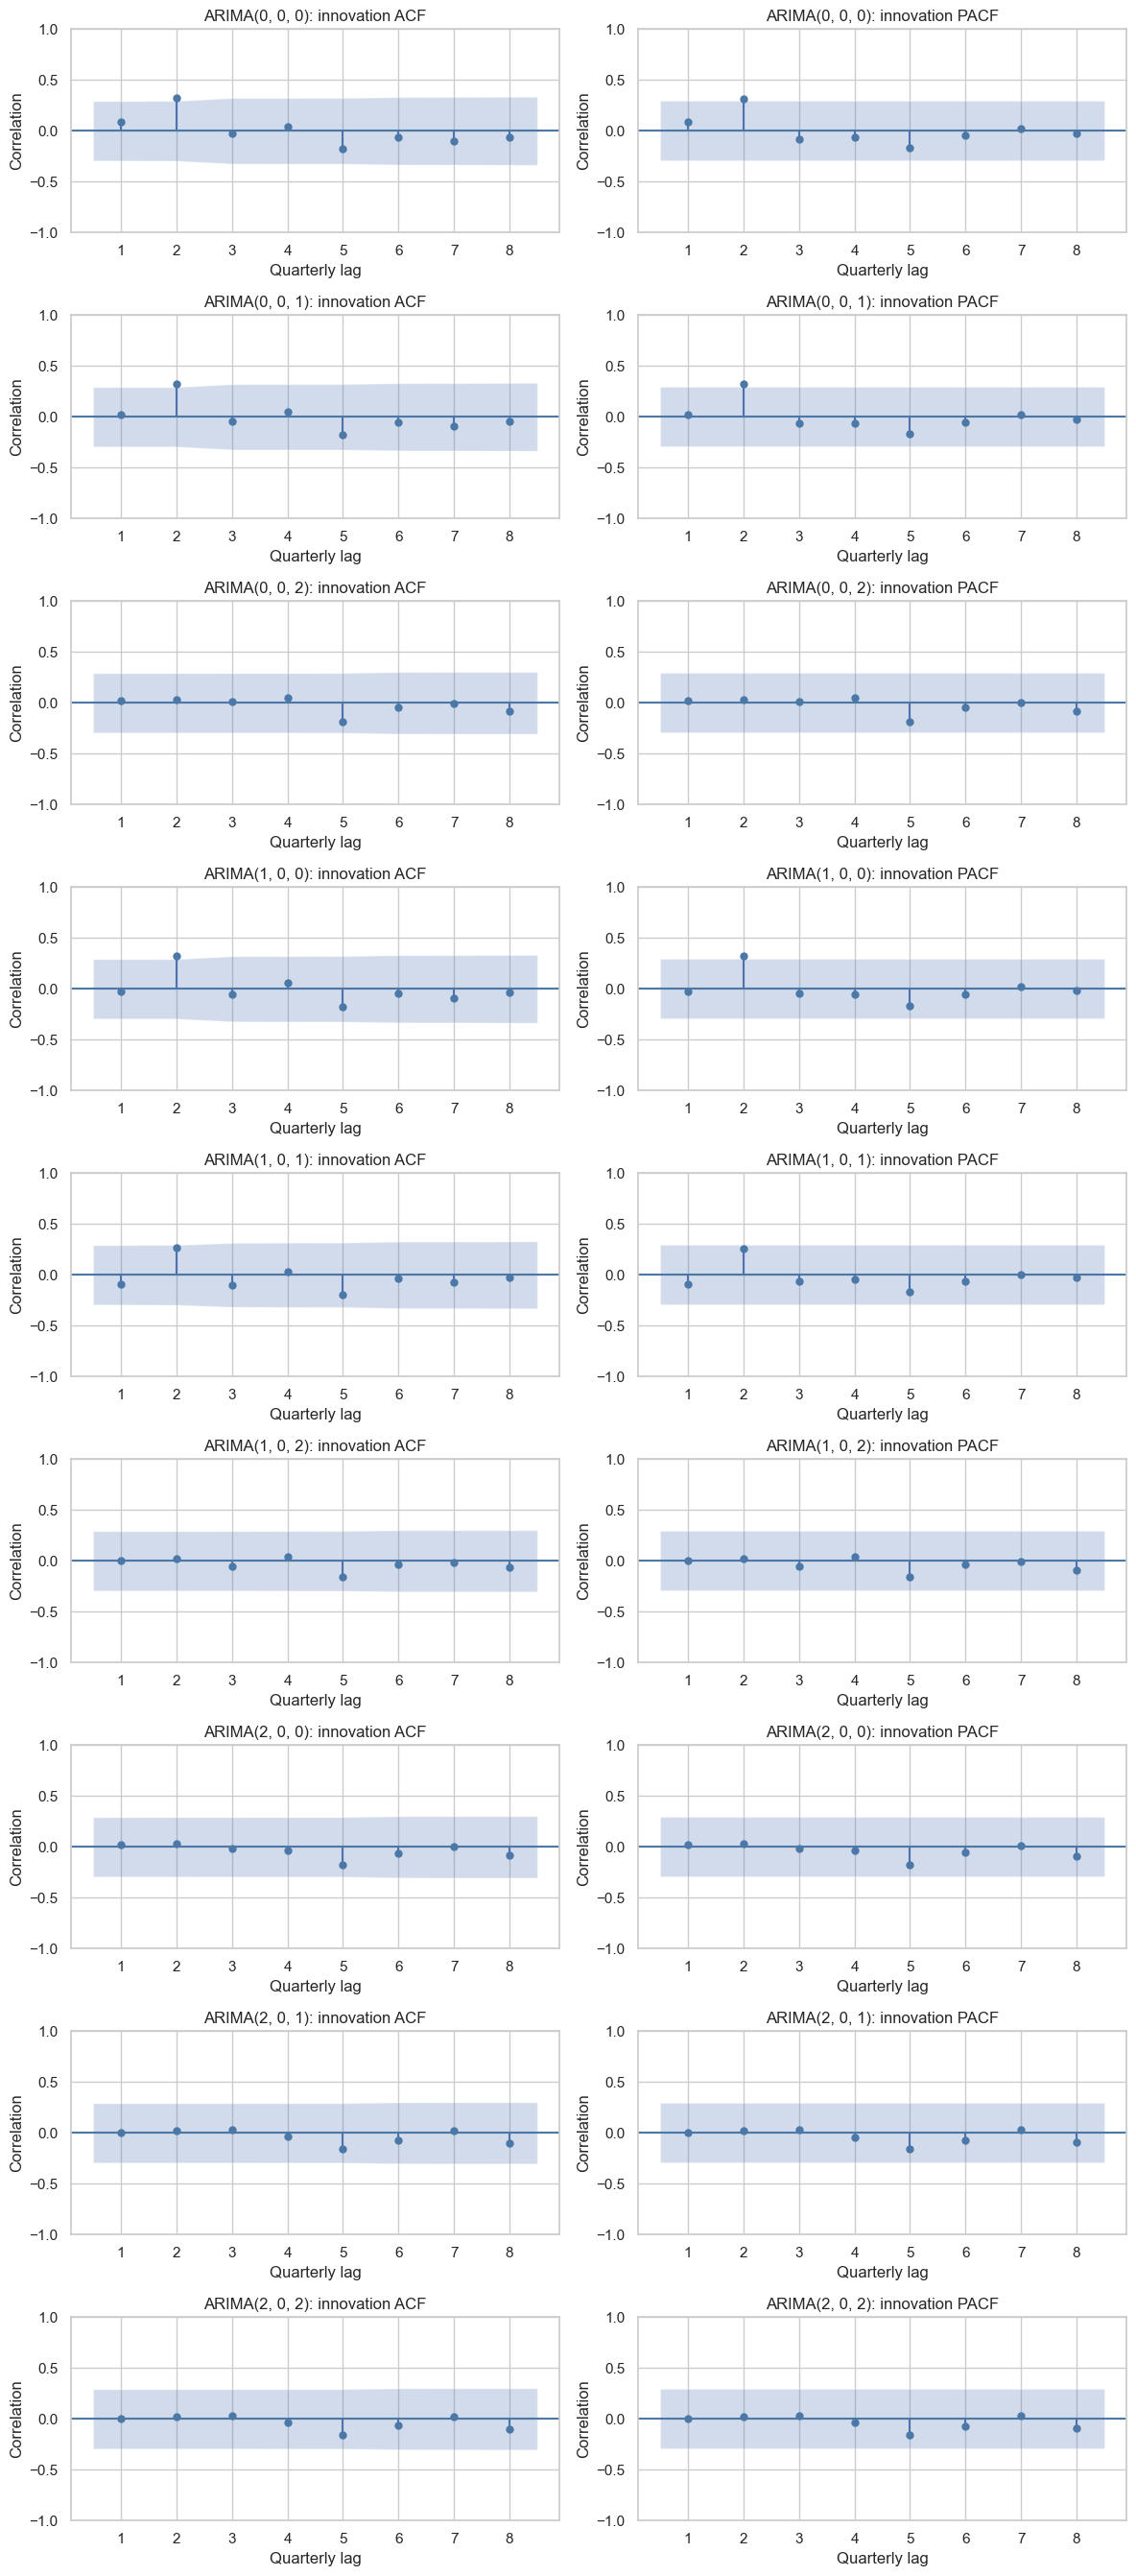

In [10]:
residual_rows = []
arima_innovations = {}
figure, axes = plt.subplots(
    len(arima_results), 2, figsize=(12, 3 * len(arima_results))
)

# check innovation dependence without using held-out observations
for row_index, (model_name, result) in enumerate(arima_results.items()):
    burn_in = max(ARIMA_DIAGNOSTIC_BURN_IN, result.loglikelihood_burn)
    innovations = pd.Series(
        result.filter_results.standardized_forecasts_error[0, burn_in:],
        index=arima_target.index[burn_in:],
        name="standardized_innovation",
    )
    assert np.isfinite(innovations.to_numpy()).all()
    assert innovations.index.max() <= TRAIN_END
    assert ARIMA_RESIDUAL_LAG < len(innovations) // 2
    arima_innovations[model_name] = innovations
    model_df = result.model.order[0] + result.model.order[2]
    assert ARIMA_RESIDUAL_LAG > model_df
    test_result = acorr_ljungbox(
        innovations,
        lags=[ARIMA_RESIDUAL_LAG],
        model_df=model_df,
        return_df=True,
    )
    p_value = test_result["lb_pvalue"].iloc[0]
    residual_rows.append({
        "model": model_name,
        "diagnostic_observations": len(innovations),
        "excluded_initial_quarters": burn_in,
        "test_lag": ARIMA_RESIDUAL_LAG,
        "model_df": model_df,
        "ljung_box_stat": test_result["lb_stat"].iloc[0],
        "ljung_box_p": p_value,
        "reject_at_5pct": p_value < 0.05,
    })

    plot_acf(
        innovations,
        lags=ARIMA_RESIDUAL_LAG,
        zero=False,
        alpha=0.05,
        color="#4C78A8",
        ax=axes[row_index, 0],
        title=f"{model_name}: innovation ACF",
    )
    plot_pacf(
        innovations,
        lags=ARIMA_RESIDUAL_LAG,
        zero=False,
        alpha=0.05,
        method="ywm",
        color="#4C78A8",
        ax=axes[row_index, 1],
        title=f"{model_name}: innovation PACF",
    )
    for axis in axes[row_index]:
        axis.set(xlabel="Quarterly lag", ylabel="Correlation")

arima_residual_diagnostics = pd.DataFrame(residual_rows).set_index("model")
assert np.isfinite(
    arima_residual_diagnostics[["ljung_box_stat", "ljung_box_p"]].to_numpy()
).all()
display(arima_residual_diagnostics)

# display the diagnostic figure, then release its memory
figure.tight_layout()
plt.show()
plt.close(figure)

## Conclusion

All nine models converged on 47 pre-2022 changes. AR(2) has the lowest AICc, but MA(2) and the constant-mean model are close; BIC favours the latter. Residual tests do not reject through lag 8, with limited small-sample power. No forecasting winner is established. Notebook 4 examines ARX models with oil and FX; Notebook 5 will handle validation and forecasting.